# Entrenamiento estático — mapas de puntos

Este notebook es autocontenido y está pensado para ejecutarse en Colab con GPU. Usa como fuente principal `proyecto-ia2/dataset_asl/final_dataset`, procesa las imágenes con MediaPipe, entrena MobileNetV2 y guarda el modelo/checkpoints en Drive.

**Clases:** letras estáticas A–I y K–Y; J/Z se reservan para el modelo temporal. Se incluyen `space`, `nothing` y `del` si existen en el dataset. `del` funciona como retroceso en la app. No se aplica rotación; la variante de recortes usa cambios moderados de brillo/contraste.

**Reanudación:** el preprocesamiento escribe un manifiesto incremental en Drive. El entrenamiento guarda checkpoints por época y `BackupAndRestore` en Drive; al reconectar, vuelve a ejecutar las celdas de configuración, preprocesamiento y entrenamiento con la misma ruta y split. No borres las carpetas `backup/` ni `checkpoints/`.

**Datos:** el conjunto integrado variado es el principal. El ASL raw de 87.000 imágenes no se concatena automáticamente; primero revisa si contiene imágenes duplicadas con el integrado. Para usar raw como comparación, cambia `DATA_ROOT` **y** asigna un `RUN_NAME` distinto en la celda inicial, para no mezclar manifiestos, splits ni checkpoints.


In [ ]:
# Colab: instala las dependencias y conecta Drive. (Omitido en ejecución local)
# %pip install -q mediapipe==0.10.35 scikit-learn
# from google.colab import drive
# drive.mount("/content/drive")

from pathlib import Path
from PIL import Image, ImageDraw, ImageOps
import csv, hashlib, json, shutil, urllib.request, warnings
import mediapipe as mp
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
SAMPLES_PER_CLASS = 1724  # None para usar todos los archivos disponibles por clase
HEAD_EPOCHS = 8
FINETUNE_EPOCHS = 12
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Ajustado para tu entorno local en WSL Ubuntu
DRIVE_ROOT = Path("/home/juan/proyectos/notebook10").expanduser()

# Dataset variado principal.
DATA_ROOT = DRIVE_ROOT / "dataset_asl/final_dataset"
MODE = "maps"
RUN_NAME = "integrated_varied_1724"
WORK_DIR = DRIVE_ROOT / f"data/processed/proyecto_def/{MODE}/{RUN_NAME}"
EXPORT_DIR = DRIVE_ROOT / f"exports/proyecto_def/{MODE}/{RUN_NAME}"
MAPS_DIR = WORK_DIR / "maps"
CROPS_DIR = WORK_DIR / "crops"
MANIFEST = WORK_DIR / "manifest.csv"
SPLIT_FILE = WORK_DIR / "split.csv"
MODEL_ASSET = DRIVE_ROOT / "exports/proyecto_def/hand_landmarker.task"
WORK_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"No encuentro el dataset integrado: {DATA_ROOT}")
if not MODEL_ASSET.exists():
    MODEL_ASSET.parent.mkdir(parents=True, exist_ok=True)
    url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
    urllib.request.urlretrieve(url, MODEL_ASSET)

LETTERS = [c for c in "ABCDEFGHIJKLMNOPQRSTUVWXYZ" if c not in {"J", "Z"}]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def normalize_label(name):
    value = name.strip().lower()
    aliases = {"delete": "del", "backspace": "del", "nothing": "nothing", "space": "space"}
    return value.upper() if len(value) == 1 else aliases.get(value, value)

folder_by_label = {}
for folder in DATA_ROOT.iterdir():
    if folder.is_dir():
        label = normalize_label(folder.name)
        if label in folder_by_label:
            raise ValueError(f"Carpetas duplicadas para clase {label}: {folder_by_label[label]} y {folder}")
        folder_by_label[label] = folder
missing = sorted(set(LETTERS) - set(folder_by_label))
if missing:
    raise ValueError(f"Faltan carpetas de letras estáticas: {missing}; revisa DATA_ROOT")
SPECIALS = [label for label in ("space", "nothing", "del") if label in folder_by_label]
CLASSES = LETTERS + SPECIALS
CLASS_TO_ID = {label: index for index, label in enumerate(CLASSES)}
print("Raíz:", DATA_ROOT)
print("Clases usadas:", CLASSES)
print("Clases J/Z excluidas; las reconoce la rama temporal.")
print("Salida y checkpoints en:", EXPORT_DIR)

Raíz: /home/juan/proyectos/notebook10/dataset_asl/final_dataset
Clases usadas: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'space', 'nothing', 'del']
Clases J/Z excluidas; las reconoce la rama temporal.
Salida y checkpoints en: /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724


## Preprocesar con recuperación

Puedes ejecutar esta celda otra vez si Colab se desconecta. Los archivos procesados y el manifiesto persistente permiten continuar sin repetir los que ya quedaron completos.

In [ ]:
# Construcción del conjunto balanceado y preprocesamiento reanudable.
def choose_sources():
    rows = []
    for label in CLASSES:
        files = sorted(p for p in folder_by_label[label].rglob("*")
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        if SAMPLES_PER_CLASS is not None and len(files) > SAMPLES_PER_CLASS:
            rng = np.random.default_rng(SEED + sum(map(ord, label)))
            idx = np.sort(rng.choice(len(files), size=SAMPLES_PER_CLASS, replace=False))
            files = [files[i] for i in idx]
        rows.extend({"source": p, "source_rel": p.relative_to(DATA_ROOT).as_posix(), "label": label}
                    for p in files)
    counts = pd.Series([r["label"] for r in rows]).value_counts().reindex(CLASSES, fill_value=0)
    display(counts.rename("seleccionadas").to_frame())
    return rows

FINGER_COLORS = [(255,90,90),(255,210,40),(80,235,100),(50,190,255),(220,90,255)]
FINGER_EDGES = [[(0,1),(1,2),(2,3),(3,4)],[(0,5),(5,6),(6,7),(7,8)],
                [(0,9),(9,10),(10,11),(11,12)],[(0,13),(13,14),(14,15),(15,16)],
                [(0,17),(17,18),(18,19),(19,20)]]
PALM_EDGES = [(5,9),(9,13),(13,17)]
POINT_COLORS = {**{i:FINGER_COLORS[0] for i in range(1,5)},
                **{i:FINGER_COLORS[1] for i in range(5,9)},
                **{i:FINGER_COLORS[2] for i in range(9,13)},
                **{i:FINGER_COLORS[3] for i in range(13,17)},
                **{i:FINGER_COLORS[4] for i in range(17,21)},0:(255,255,255)}

def landmarks_to_map(hand):
    xy = np.asarray([(p.x,p.y) for p in hand], dtype=np.float32)
    if xy.shape != (21,2) or not np.isfinite(xy).all(): return None
    xy -= xy[0]
    scale = float(np.linalg.norm(xy[9]))
    if scale < 1e-6: return None
    xy /= scale
    extent = float(np.max(np.abs(xy)))
    if extent < 1e-6: return None
    xy = xy / extent * 0.40 * (IMAGE_SIZE-1) + (IMAGE_SIZE-1)/2
    pts = [(int(round(x)),int(round(y))) for x,y in xy]
    canvas = Image.new("RGB",(IMAGE_SIZE,IMAGE_SIZE),(0,0,0)); draw = ImageDraw.Draw(canvas)
    width, radius = max(2,IMAGE_SIZE//70), max(3,IMAGE_SIZE//48)
    for edges,color in zip(FINGER_EDGES,FINGER_COLORS):
        for a,b in edges: draw.line((pts[a],pts[b]),fill=color,width=width)
    for a,b in PALM_EDGES: draw.line((pts[a],pts[b]),fill=(235,235,235),width=width)
    for i,(x,y) in enumerate(pts):
        draw.ellipse((x-radius,y-radius,x+radius,y+radius),fill=POINT_COLORS[i],outline=(255,255,255))
    return canvas

def crop_from_image(image, hand, margin=0.30):
    points = np.asarray([(p.x*image.width,p.y*image.height) for p in hand],dtype=np.float32)
    x0,y0 = points.min(axis=0); x1,y1 = points.max(axis=0)
    side = max(float(max(x1-x0,y1-y0)),2.0)*(1+2*margin)
    cx,cy=(x0+x1)/2,(y0+y1)/2
    left,top=int(round(cx-side/2)),int(round(cy-side/2)); side=max(int(round(side)),2)
    right,bottom=left+side,top+side
    result=Image.new("RGB",(side,side),(0,0,0))
    box=(max(0,left),max(0,top),min(image.width,right),min(image.height,bottom))
    if box[2] <= box[0] or box[3] <= box[1]: return None
    result.paste(image.crop(box),(box[0]-left,box[1]-top))
    return result.resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.BILINEAR)

def make_detector():
    options=mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(MODEL_ASSET)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,num_hands=1,
        min_hand_detection_confidence=0.5,min_hand_presence_confidence=0.5)
    return mp.tasks.vision.HandLandmarker.create_from_options(options)

def prepare_images():
    output_root = MAPS_DIR if MODE == "maps" else CROPS_DIR
    output_root.mkdir(parents=True,exist_ok=True)
    previous={}
    if MANIFEST.exists():
        old=pd.read_csv(MANIFEST).drop_duplicates("source_rel",keep="last")
        previous={str(r.source_rel):r._asdict() for r in old.itertuples(index=False)}
    append_header=not MANIFEST.exists() or MANIFEST.stat().st_size==0
    detector=make_detector(); rows=[]
    try:
        with MANIFEST.open("a",newline="",encoding="utf-8") as stream:
            writer=csv.DictWriter(stream,fieldnames=["source_rel","label","output_rel","detected","error"])
            if append_header: writer.writeheader()
            sources=choose_sources()
            for i,row in enumerate(sources,1):
                rel=row["source_rel"]
                name=hashlib.sha1(rel.encode("utf-8")).hexdigest()+(".png" if MODE=="maps" else ".jpg")
                output_rel=f"{row['label']}/{name}"; destination=output_root/output_rel
                old=previous.get(rel)
                if old and destination.is_file():
                    rows.append(old); continue
                destination.parent.mkdir(parents=True,exist_ok=True)
                detected=False; error=""
                try:
                    with Image.open(row["source"]) as raw:
                        image=ImageOps.exif_transpose(raw).convert("RGB")
                    if row["label"]=="nothing":
                        result=Image.new("RGB",(IMAGE_SIZE,IMAGE_SIZE),(0,0,0))
                    else:
                        rgb=np.asarray(image)
                        result_mp=detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB,data=rgb))
                        if result_mp.hand_landmarks:
                            hand=result_mp.hand_landmarks[0]
                            if MODE=="maps": result=landmarks_to_map(hand)
                            else: result=crop_from_image(image,hand)
                            detected=result is not None
                        else: result=None
                    if result is None: result=Image.new("RGB",(IMAGE_SIZE,IMAGE_SIZE),(0,0,0))
                    result.save(destination,format="PNG" if MODE=="maps" else "JPEG",quality=95)
                except Exception as exc:
                    error=f"{type(exc).__name__}: {exc}"
                    result=Image.new("RGB",(IMAGE_SIZE,IMAGE_SIZE),(0,0,0))
                    result.save(destination,format="PNG" if MODE=="maps" else "JPEG",quality=95)
                record={"source_rel":rel,"label":row["label"],"output_rel":output_rel,
                        "detected":int(detected),"error":error}
                writer.writerow(record); rows.append(record)
                if i%25==0 or i==len(sources):
                    stream.flush(); print(f"{i}/{len(sources)} procesadas | última: {rel}")
    finally: detector.close()
    return pd.DataFrame(rows).drop_duplicates("source_rel",keep="last")

manifest_df=prepare_images()
display(manifest_df.groupby(["label","detected"]).size().unstack(fill_value=0))


libEGL warning: DRI3 error: Could not get DRI3 device
libEGL warning: Ensure your X server supports DRI3 to get accelerated rendering
I0000 00:00:1794840880.215819   51547 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1794840880.266388   51598 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: llvmpipe (LLVM 21.1.8, 256 bits)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794840880.297750   51550 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794840880.314422   51563 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


,seleccionadas
A,1724
B,1724
C,1724
D,1724
E,1724
F,1724
G,1724
H,1724
I,1724
K,1724


W0000 00:00:1794840881.512878   51557 landmark_projection_calculator.cc:78] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


25/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01084.jpg
50/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01109.jpg
75/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01134.jpg
100/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01159.jpg
125/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01184.jpg
150/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01209.jpg
175/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01234.jpg
200/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01259.jpg
225/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Gestures_01284.jpg
250/46548 procesadas | última: A/A_Images of American Sign Language (ASL) Alphabet Ge

detected,0,1
label,,
A,594,1130
B,426,1298
C,620,1104
D,398,1326
E,471,1253
F,215,1509
G,350,1374
H,407,1317
I,392,1332


## Split y entrenamiento

El split es estratificado por clase a nivel de imagen (70/15/15). Si hay copias idénticas entre particiones, las métricas pueden ser optimistas; conserva `source_rel` y revisa duplicados/procedencia.

In [ ]:
# Filtra fallos de detección y fija las particiones para poder reanudar.
usable=manifest_df[(manifest_df.detected.astype(int)==1) | (manifest_df.label=="nothing")].copy()
counts=usable.label.value_counts()
too_small=counts[counts<10]
if not too_small.empty: raise ValueError(f"Clases con menos de 10 ejemplos utilizables: {too_small.to_dict()}")

if SPLIT_FILE.exists():
    split_df=pd.read_csv(SPLIT_FILE)
    if set(split_df.source_rel)!=set(usable.source_rel):
        raise ValueError("Cambió el conjunto procesado desde la partición anterior. Renombra/elimina split.csv para crear otra partición.")
else:
    train_val,test=train_test_split(usable,test_size=0.15,random_state=SEED,stratify=usable.label)
    train,val=train_test_split(train_val,test_size=(0.15/0.85),random_state=SEED,stratify=train_val.label)
    split_df=pd.concat([train.assign(split="train"),val.assign(split="validation"),test.assign(split="test")],ignore_index=True)
    split_df.to_csv(SPLIT_FILE,index=False)
display(split_df.groupby(["split","label"]).size().unstack(fill_value=0))
train_df=split_df[split_df.split=="train"].copy()
val_df=split_df[split_df.split=="validation"].copy()
test_df=split_df[split_df.split=="test"].copy()
output_root=MAPS_DIR if MODE=="maps" else CROPS_DIR

def make_dataset(frame,training=False):
    paths=[str(output_root/p) for p in frame.output_rel.astype(str)]
    labels=frame.label.map(CLASS_TO_ID).to_numpy(dtype=np.int32)
    ds=tf.data.Dataset.from_tensor_slices((paths,labels))
    if training: ds=ds.shuffle(len(frame),seed=SEED,reshuffle_each_iteration=True)
    def load(path,label):
        image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
        image=tf.image.resize(image,(IMAGE_SIZE,IMAGE_SIZE),antialias=True)
        image=tf.cast(image,tf.float32)
        if training and MODE=="crop":
            image=tf.image.random_contrast(image,0.85,1.15)
            image=tf.image.random_brightness(image,max_delta=15.0)
            image=tf.clip_by_value(image,0.0,255.0)
        return image,label
    return ds.map(load,num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds=make_dataset(train_df,True); val_ds=make_dataset(val_df); test_ds=make_dataset(test_df)

def build_model():
    inputs=tf.keras.Input((IMAGE_SIZE,IMAGE_SIZE,3),name="static_image")
    x=tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    backbone=tf.keras.applications.MobileNetV2(include_top=False,weights="imagenet",
        input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),name="mobilenetv2_backbone")
    backbone.trainable=False
    x=backbone(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D()(x)
    x=tf.keras.layers.Dropout(0.30)(x)
    outputs=tf.keras.layers.Dense(len(CLASSES),activation="softmax",dtype="float32",name="class_probs")(x)
    model=tf.keras.Model(inputs,outputs,name=f"mobilenetv2_{MODE}")
    return model

def callbacks_for(phase):
    checkpoint_dir=EXPORT_DIR/"checkpoints"/phase
    checkpoint_dir.mkdir(parents=True,exist_ok=True)
    return [
        tf.keras.callbacks.BackupAndRestore(backup_dir=str(EXPORT_DIR/"backup"/phase),save_freq="epoch"),
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint_dir/"best.keras"),monitor="val_loss",
            mode="min",save_best_only=True,verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint_dir/"epoch-{epoch:02d}.weights.h5"),
            save_weights_only=True,save_best_only=False,save_freq="epoch"),
        tf.keras.callbacks.CSVLogger(str(EXPORT_DIR/f"history_{phase}.csv"),append=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=1,min_lr=1e-6),
    ]

def train_or_resume():
    final_path=EXPORT_DIR/"model.keras"
    if final_path.exists() and (EXPORT_DIR/"training_complete.json").exists():
        print("Entrenamiento completo ya existe; cargo el modelo guardado.")
        return tf.keras.models.load_model(final_path,compile=False)
    head_best=EXPORT_DIR/"checkpoints/head/best.keras"
    head_done=EXPORT_DIR/"head_complete.json"
    if head_done.exists() and head_best.exists():
        model=tf.keras.models.load_model(head_best,compile=False)
    else:
        model=build_model()
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                      loss="sparse_categorical_crossentropy",metrics=["accuracy"])
        model.fit(train_ds,validation_data=val_ds,epochs=HEAD_EPOCHS,callbacks=callbacks_for("head"),verbose=2)
        if not head_best.exists(): raise RuntimeError("No se guardó el checkpoint de la cabeza.")
        head_done.write_text(json.dumps({"complete":True}),encoding="utf-8")
        model=tf.keras.models.load_model(head_best,compile=False)
    backbone=model.get_layer("mobilenetv2_backbone")
    backbone.trainable=True
    for layer in backbone.layers[:-30]: layer.trainable=False
    for layer in backbone.layers:
        if isinstance(layer,tf.keras.layers.BatchNormalization): layer.trainable=False
    fine_best=EXPORT_DIR/"checkpoints/finetune/best.keras"
    fine_done=EXPORT_DIR/"finetune_complete.json"
    if fine_done.exists() and fine_best.exists():
        model=tf.keras.models.load_model(fine_best,compile=False)
    else:
        model.compile(optimizer=tf.keras.optimizers.Adam(5e-5),
                      loss="sparse_categorical_crossentropy",metrics=["accuracy"])
        model.fit(train_ds,validation_data=val_ds,epochs=FINETUNE_EPOCHS,
                  callbacks=callbacks_for("finetune"),verbose=2)
        if not fine_best.exists(): raise RuntimeError("No se guardó el checkpoint de fine-tuning.")
        fine_done.write_text(json.dumps({"complete":True}),encoding="utf-8")
        model=tf.keras.models.load_model(fine_best,compile=False)
    model.save(final_path)
    (EXPORT_DIR/"classes.json").write_text(json.dumps(CLASSES,ensure_ascii=False,indent=2),encoding="utf-8")
    (EXPORT_DIR/"metadata.json").write_text(json.dumps({"mode":MODE,"image_size":IMAGE_SIZE,
        "classes":CLASSES,"source":str(DATA_ROOT),"run_name":RUN_NAME,
        "preprocessing":"MediaPipe map" if MODE=="maps" else "MediaPipe square crop",
        "crop_margin":0.30 if MODE=="crop" else None,"seed":SEED},ensure_ascii=False,indent=2),encoding="utf-8")
    shutil.copy2(MODEL_ASSET,EXPORT_DIR/"hand_landmarker.task")
    (EXPORT_DIR/"training_complete.json").write_text(json.dumps({"complete":True}),encoding="utf-8")
    return model

model=train_or_resume()


label,A,B,C,D,E,F,G,H,I,K,...,S,T,U,V,W,X,Y,del,nothing,space
split,,,,,,,,,,,,,,,,,,,,,
test,169,195,166,199,188,226,206,198,200,206,...,174,169,196,192,195,181,189,147,259,122
train,791,908,773,928,877,1057,962,922,932,959,...,813,787,913,895,912,844,884,684,1206,572
validation,170,195,165,199,188,226,206,197,200,206,...,174,169,196,192,195,181,190,146,259,122


I0000 00:00:1794841792.441335   51457 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9
E0000 00:00:1794841792.527821   51457 cuda_executor.cc:1365] [0] Failed to allocate device memory of 5.43GiB (5830082560 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E0000 00:00:1794841792.528664   51457 cuda_executor.cc:1365] [0] Failed to allocate device memory of 4.89GiB (5247074304 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
exter

Epoch 1/8


/home/juan/proyectos/notebook10/env_asl/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794841796.800059   51457 service.cc:154] XLA service 0x274e90a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794841796.800095   51457 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4060, Compute Capability 8.9 (Driver: 13.5.0[621.24.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794841796.848617   51457 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794841797.453634   51457 cuda_dnn.cc:442] Loaded cuDNN version 92801
W0000 00:00:1794841798.680735   53500 cuda_timer


Epoch 1: val_loss improved from None to 0.59040, saving model to /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724/checkpoints/head/best.keras

Epoch 1: finished saving model to /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724/checkpoints/head/best.keras
720/720 - 41s - 57ms/step - accuracy: 0.7445 - loss: 0.9641 - val_accuracy: 0.8483 - val_loss: 0.5904 - learning_rate: 0.0010
Epoch 2/8

Epoch 2: val_loss improved from 0.59040 to 0.47382, saving model to /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724/checkpoints/head/best.keras

Epoch 2: finished saving model to /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724/checkpoints/head/best.keras
720/720 - 22s - 30ms/step - accuracy: 0.8649 - loss: 0.5121 - val_accuracy: 0.8742 - val_loss: 0.4738 - learning_rate: 0.0010
Epoch 3/8

Epoch 3: val_loss improved from 0.47382 to 0.44231, saving model to /home/juan/proyect

## Evaluación y exportación

El conjunto test se reserva antes de entrenar y solo se usa en esta celda.

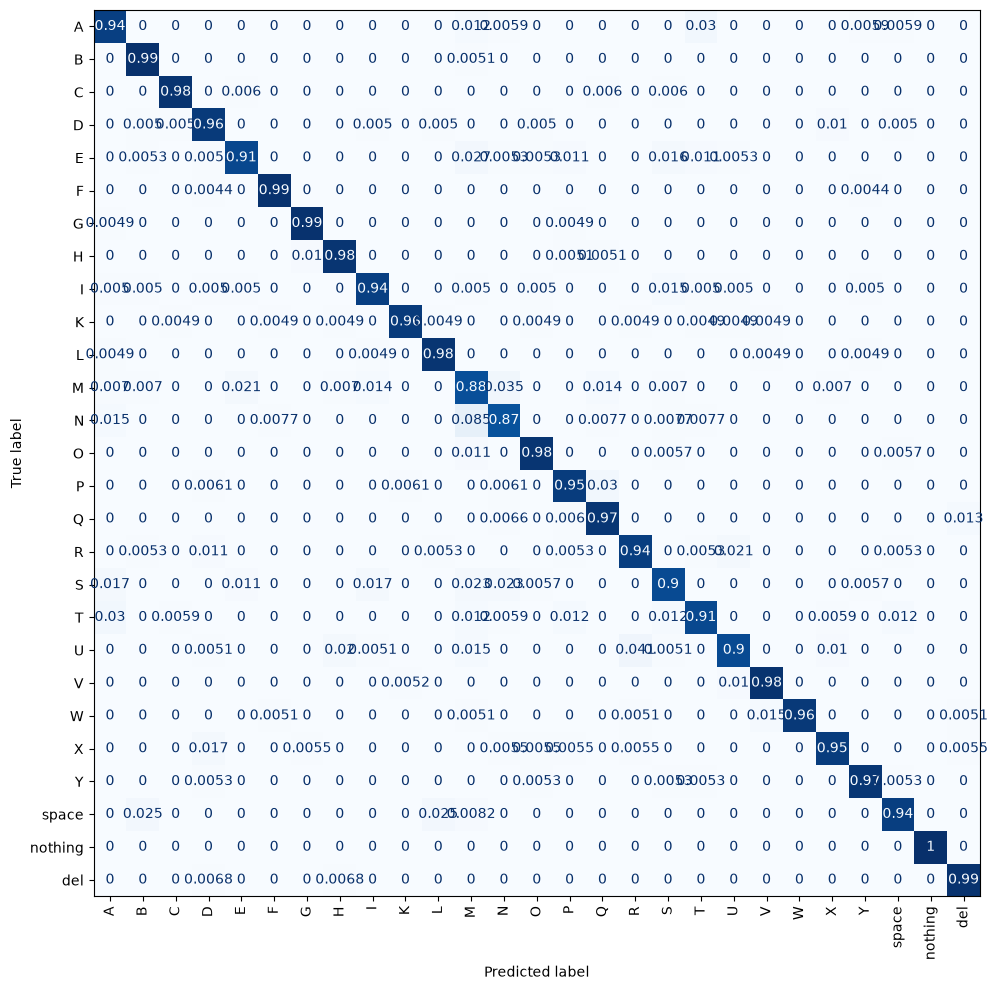

{'n_test': 4936, 'accuracy': 0.9554294975688817, 'macro_f1': 0.9521417944965582}
Modelo, clases, configuración y checkpoints: /home/juan/proyectos/notebook10/exports/proyecto_def/maps/integrated_varied_1724


In [ ]:
# Evaluación final en la partición de prueba (no se usa para ajustar hiperparámetros).
y_true=test_df.label.map(CLASS_TO_ID).to_numpy(dtype=np.int32)
y_prob=model.predict(test_ds,verbose=0)
y_pred=y_prob.argmax(axis=1)
metrics={"n_test":int(len(test_df)),"accuracy":float(accuracy_score(y_true,y_pred)),
         "macro_f1":float(f1_score(y_true,y_pred,average="macro",zero_division=0)),
         "classification_report":classification_report(y_true,y_pred,labels=list(range(len(CLASSES))),
             target_names=CLASSES,output_dict=True,zero_division=0)}
(EXPORT_DIR/"metrics.json").write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding="utf-8")
pd.DataFrame({"source_rel":test_df.source_rel,"true":[CLASSES[i] for i in y_true],
              "prediction":[CLASSES[i] for i in y_pred]}).to_csv(EXPORT_DIR/"test_predictions.csv",index=False)
cm=confusion_matrix(y_true,y_pred,labels=list(range(len(CLASSES))),normalize="true")
fig,ax=plt.subplots(figsize=(12,10))
ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,xticks_rotation=90,cmap="Blues",colorbar=False)
fig.tight_layout(); fig.savefig(EXPORT_DIR/"confusion_matrix.png",dpi=140); plt.show()
print({k:v for k,v in metrics.items() if k!="classification_report"})
print("Modelo, clases, configuración y checkpoints:",EXPORT_DIR)
